<a href="https://colab.research.google.com/github/ritika-adk/AI_Ml-BootCamp/blob/main/pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

00.PyTorch Fundamentals


In [ ]:
import torch
torch.__version__

'2.14.1+cu130'

In [ ]:
#2
tensor_1=torch.rand(size=(7,7))
tensor_1,tensor_1.shape

(tensor([[0.4614, 0.9723, 0.8704, 0.3729, 0.5369, 0.4970, 0.8323],
         [0.5709, 0.5873, 0.7201, 0.7036, 0.4926, 0.3731, 0.9723],
         [0.4757, 0.8357, 0.5283, 0.4414, 0.7484, 0.6459, 0.1836],
         [0.9911, 0.5490, 0.9817, 0.9792, 0.9263, 0.0816, 0.8953],
         [0.4642, 0.6933, 0.8446, 0.8263, 0.0674, 0.3441, 0.0176],
         [0.5435, 0.7287, 0.9040, 0.1409, 0.9375, 0.7638, 0.4996],
         [0.7328, 0.2931, 0.8933, 0.1124, 0.0095, 0.0273, 0.1194]]),
 torch.Size([7, 7]))

In [ ]:
#3
tensor_2=torch.rand(size=(1,7))
tensor_3=torch.matmul(tensor_1,tensor_2.T)
tensor_3,tensor_3.shape


(tensor([[2.5143],
         [2.3867],
         [2.2271],
         [3.0437],
         [2.5286],
         [2.4383],
         [1.8393]]),
 torch.Size([7, 1]))

In [ ]:
#4
torch.manual_seed(0)

X=torch.rand(size=(7,7))
Y=torch.rand(size=(1,7))
Z=torch.matmul(X,Y.T)
Z,Z.shape

(tensor([[1.8542],
         [1.9611],
         [2.2884],
         [3.0481],
         [1.7067],
         [2.5290],
         [1.7989]]),
 torch.Size([7, 1]))

In [ ]:
#5
# Set random seed on the GPU
torch.cuda.manual_seed(1234)
Z.device

device(type='cpu')

In [11]:
#6

# Set random seed
torch.manual_seed(1234)

print(torch.cuda.is_available())

# Check for access to GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

# Create two random tensors on GPU
tensor_M= torch.rand(size=(2,3)).to(device)
tensor_N = torch.rand(size=(2,3)).to(device)
tensor_M, tensor_N


True
Device: cuda


(tensor([[0.0290, 0.4019, 0.2598],
         [0.3666, 0.0583, 0.7006]], device='cuda:0'),
 tensor([[0.0518, 0.4681, 0.6738],
         [0.3315, 0.7837, 0.5631]], device='cuda:0'))

In [ ]:
#7
tensor_Z=torch.matmul(tensor_M,tensor_N.T)
tensor_Z,tensor_Z.shape

(tensor([[0.3647, 0.4709],
         [0.5184, 0.5617]], device='cuda:0'),
 torch.Size([2, 2]))

In [ ]:
#8
max=torch.max(tensor_Z)
min=torch.min(tensor_Z)
max,min

(tensor(0.5617, device='cuda:0'), tensor(0.3647, device='cuda:0'))

In [ ]:
#9
ind_max=torch.argmax(tensor_Z)
ind_min=torch.argmin(tensor_Z)
ind_max,ind_min

(tensor(3, device='cuda:0'), tensor(0, device='cuda:0'))

In [ ]:
#10
torch.manual_seed(7)
tensor=torch.rand(size=(1,1,1,10))
new_tensor=tensor.squeeze()
tensor,tensor.shape,new_tensor,new_tensor.shape

(tensor([[[[0.5349, 0.1988, 0.6592, 0.6569, 0.2328, 0.4251, 0.2071, 0.6297,
            0.3653, 0.8513]]]]),
 torch.Size([1, 1, 1, 10]),
 tensor([0.5349, 0.1988, 0.6592, 0.6569, 0.2328, 0.4251, 0.2071, 0.6297, 0.3653,
         0.8513]),
 torch.Size([10]))

01 PyTorch Workflow Fundamentals
Exercise


In [1]:
import torch
import matplotlib.pyplot as plt
from torch import nn


print(torch.__version__)
decice="cuda" if torch.cuda.is_available() else "cpu"
decice


2.14.1+cu130


'cuda'

In [4]:
#1 Create a straight line dataset using the linear regression formula (weight * X + bias).
weight=0.3
bias=0.9
start=0
end=1
step=0.01
X=torch.arange(start,end,step).unsqueeze(dim=1)
y=weight*X+bias
print(f"Number of X samples:{len(X)}")
print(f"Number of Y samples:{len(y)}")
print(f"First 10 X & y samples:\nX: {X[:10]}\ny: {y[:10]}")


Number of X samples:100
Number of Y samples:100
First 10 X & y samples:
X: tensor([[0.0000],
        [0.0100],
        [0.0200],
        [0.0300],
        [0.0400],
        [0.0500],
        [0.0600],
        [0.0700],
        [0.0800],
        [0.0900]])
y: tensor([[0.9000],
        [0.9030],
        [0.9060],
        [0.9090],
        [0.9120],
        [0.9150],
        [0.9180],
        [0.9210],
        [0.9240],
        [0.9270]])


In [5]:
#splitting the data in training set and testing set

train_split=int(0.8*len(X))
X_train,y_train=X[:train_split],y[:train_split]
X_test,y_test=X[train_split:],y[train_split:]
len(X_train),len(y_train),len(X_test),len(y_test)

(80, 80, 20, 20)

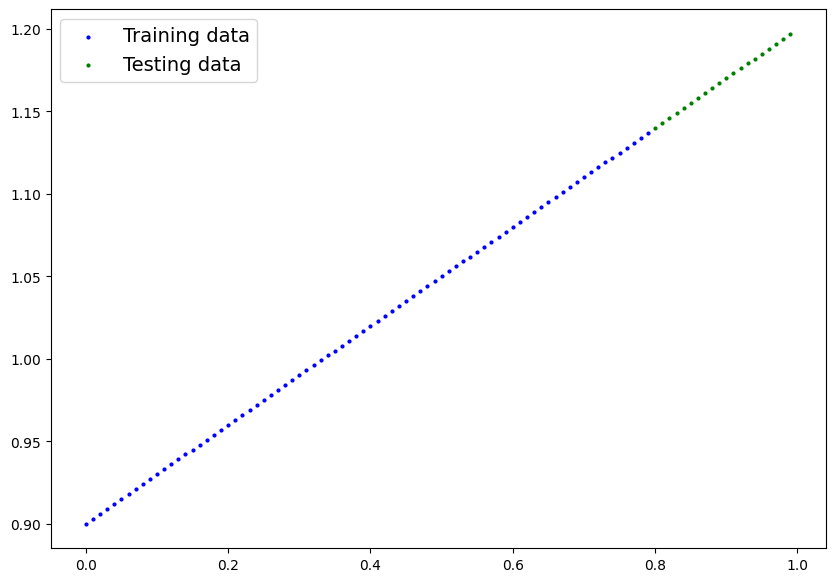

In [6]:
#Visualizing training and testing data

def plot_predictions(train_data=X_train,train_labels=y_train,test_data=X_test,test_labels=y_test,predictions=None):
  plt.figure(figsize=(10,7))
  plt.scatter(train_data,train_labels,c="b",s=4,label="Training data")
  plt.scatter(test_data,test_labels,c="g",s=4,label="Testing data")
  if predictions is not None:
    plt.scatter(test_data,predictions,c="r",s=4,label="Predictions")
  plt.legend(prop={"size":14})
plot_predictions()

In [9]:
#2 Build a PyTorch model by subclassing nn.Module.

class LinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear_layer=nn.Linear(in_features=1,out_features=1)

  def forward(self,x:torch.Tensor)-> torch.Tensor:
    return self.linear_layer(x)


torch.manual_seed(42)
model_0=LinearRegressionModel()
model_0,model_0.state_dict()

(LinearRegressionModel(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [14]:
#put the model and its parameters to the target device
model_0 = model_0.to(device)
next(model_0.parameters()).device
list(model_0.parameters())



[Parameter containing:
 tensor([[0.7645]], device='cuda:0', requires_grad=True),
 Parameter containing:
 tensor([0.8300], device='cuda:0', requires_grad=True)]

In [16]:

#3  Create a loss function and optimizer using nn.L1Loss() and torch.optim.SGD(params, lr) respectively.

loss_function=nn.L1Loss()
optimizer=torch.optim.SGD(params=model_0.parameters(),lr=0.01)

#training loop
torch.manual_seed(42)
epochs=250

X_train=X_train.to(device)
X_test=X_test.to(device)
y_train=y_train.to(device)
y_test=y_test.to(device)

for epoch in range(epochs):
  model_0.train()# putting the model in train mode

  #forward pass
  y_pred=model_0(X_train)

  #Calculate loss
  loss=loss_function(y_pred,y_train)

  #Zero gradients
  optimizer.zero_grad()

  #Backpropagation
  loss.backward()

  #step the optimizer
  optimizer.step()

  if epoch%10==0:
    model_0.eval()
    with torch.inference_mode():
      test_pred=model_0(X_test)
      test_loss=loss_function(test_pred,y_test)
      print(f"Epoch{epoch}|Train loss:{loss:.2f}|Test loss:{test_loss:.2f}")




Epoch0|Train loss:0.13|Test loss:0.34
Epoch10|Train loss:0.09|Test loss:0.26
Epoch20|Train loss:0.08|Test loss:0.22
Epoch30|Train loss:0.08|Test loss:0.19
Epoch40|Train loss:0.07|Test loss:0.17
Epoch50|Train loss:0.07|Test loss:0.16
Epoch60|Train loss:0.07|Test loss:0.15
Epoch70|Train loss:0.06|Test loss:0.15
Epoch80|Train loss:0.06|Test loss:0.14
Epoch90|Train loss:0.05|Test loss:0.13
Epoch100|Train loss:0.05|Test loss:0.12
Epoch110|Train loss:0.05|Test loss:0.11
Epoch120|Train loss:0.04|Test loss:0.10
Epoch130|Train loss:0.04|Test loss:0.10
Epoch140|Train loss:0.04|Test loss:0.09
Epoch150|Train loss:0.03|Test loss:0.08
Epoch160|Train loss:0.03|Test loss:0.07
Epoch170|Train loss:0.03|Test loss:0.06
Epoch180|Train loss:0.02|Test loss:0.06
Epoch190|Train loss:0.02|Test loss:0.05
Epoch200|Train loss:0.02|Test loss:0.04
Epoch210|Train loss:0.01|Test loss:0.03
Epoch220|Train loss:0.01|Test loss:0.02
Epoch230|Train loss:0.01|Test loss:0.02
Epoch240|Train loss:0.00|Test loss:0.01


In [21]:
#4 Make predictions with the trained model on the test data

#put the model in evaluation mode
model_0.eval()

with torch.inference_mode():
  y_preds=model_0(X_test)
y_preds

tensor([[1.1333],
        [1.1363],
        [1.1393],
        [1.1423],
        [1.1454],
        [1.1484],
        [1.1514],
        [1.1545],
        [1.1575],
        [1.1605],
        [1.1635],
        [1.1666],
        [1.1696],
        [1.1726],
        [1.1757],
        [1.1787],
        [1.1817],
        [1.1847],
        [1.1878],
        [1.1908]], device='cuda:0')

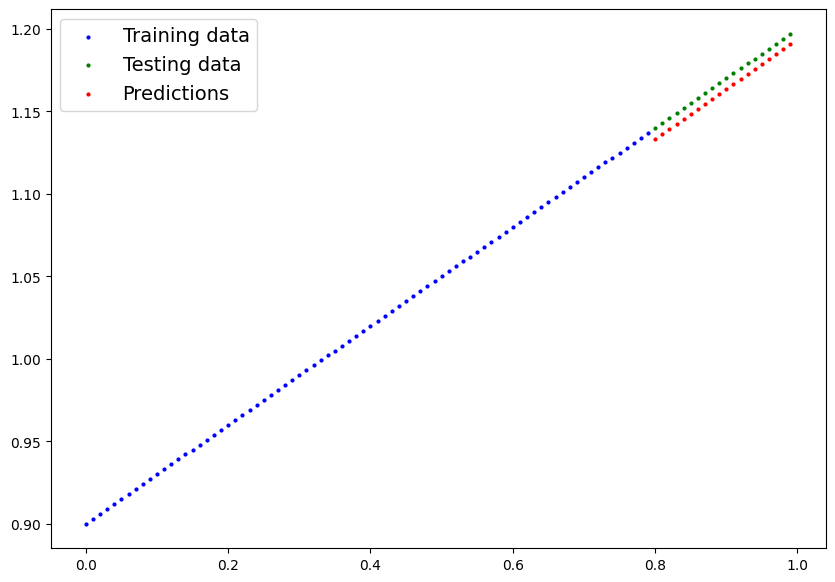

In [22]:


# Plot the predictions (these may need to be on a specific device)
plot_predictions(predictions = y_preds.cpu())


In [25]:
#5 Save your trained models state_dict to file

from pathlib import Path

#creating models dictionary
MODEL_PATH=Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

#creating model save path
MODEL_NAME="01_pytorch_workflow_model_0"
MODEL_SAVE_PATH=MODEL_PATH/MODEL_NAME

#saving the model state dict
print(f"Saving model to:{MODEL_SAVE_PATH}")
torch.save(obj = model_0.state_dict(),f = MODEL_SAVE_PATH)


Saving model to:models/01_pytorch_workflow_model_0


In [30]:
#creating new instance of the model and loading the saved state dict
loaded_model_0=LinearRegressionModel()
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))
loaded_model_0.to(device)

#putting the loaded model in evaluation mode
loaded_model_0.eval()
y_preds_new=loaded_model_0(X_test)
print(y_preds_new)
y_preds==y_preds_new


tensor([[1.1333],
        [1.1363],
        [1.1393],
        [1.1423],
        [1.1454],
        [1.1484],
        [1.1514],
        [1.1545],
        [1.1575],
        [1.1605],
        [1.1635],
        [1.1666],
        [1.1696],
        [1.1726],
        [1.1757],
        [1.1787],
        [1.1817],
        [1.1847],
        [1.1878],
        [1.1908]], device='cuda:0', grad_fn=<AddmmBackward0>)


tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]], device='cuda:0')

In [31]:
loaded_model_0.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.3028]], device='cuda:0')),
             ('linear_layer.bias', tensor([0.8910], device='cuda:0'))])